# Phase 0: Data Preparation — IC4SD-Wood-Conifer20v1

**Phase 0**: Organize dataset, create label mapping, create stratified split.

> **Note**: This notebook follows a fixed template for scalability and reproducibility.

## 1. Configuration

In [1]:
# Configuration
RAW_DATA_PATH = "../../data/raw"
OUTPUT_DIR = "../../data/split"
LABEL_MAPPING_PATH = "../../data/species_to_family.json"

# Split ratios
TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Random seed for reproducibility
RANDOM_SEED = 42

# Create output directories
import os
for split in ['train', 'val', 'test']:
    os.makedirs(f"{OUTPUT_DIR}/{split}", exist_ok=True)

In [2]:
import os
import glob
import json
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shutil
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

# Set random seeds
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

## 2. Load Exploration Results

In [3]:
import shutil
for split in ['train', 'val', 'test']:
    split_path = f"{OUTPUT_DIR}/{split}"
    if os.path.exists(split_path):
        shutil.rmtree(split_path)
    os.makedirs(split_path, exist_ok=True)


In [4]:
# Load exploration summary from Phase -1
exploration_path = "../../data/exploration/exploration_summary.json"
if os.path.exists(exploration_path):
    with open(exploration_path, 'r') as f:
        exploration = json.load(f)
    print("Exploration summary loaded:")
    print(f"  - Total species: {exploration['total_species']}")
    print(f"  - Total images: {exploration['total_images']}")
    print(f"  - Image size range: {exploration['image_size_range']}")
    if exploration['ambiguous_species']:
        print(f"  - Ambiguous species: {exploration['ambiguous_species']}")
else:
    print("Warning: Exploration summary not found. Run Phase -1 first.")

Exploration summary loaded:
  - Total species: 21
  - Total images: 6423
  - Image size range: {'min_width': 2560, 'max_width': 2560, 'min_height': 2048, 'max_height': 2048}


## 3. Define Species-to-Family Mapping

In [5]:
# Species to Family mapping based on botanical taxonomy
# Reference: WoodID_plan.md and tree.txt

SPECIES_TO_FAMILY = {
    # Cupressaceae (10 species)
    "3244.Calocedrus sp": "Cupressaceae",
    "3252.Callitris columellaris": "Cupressaceae",
    "3273.Fokienia hodginsii": "Cupressaceae",
    "3274.Cunninghamia lanceolata": "Cupressaceae",
    "3314.Cupressus funebris (Cupressus pendula)": "Cupressaceae",
    "3342.Calocedrus rupestris": "Cupressaceae",
    "3341.Xanthocyparis vietnamensis": "Cupressaceae",
    "3350.Cryptomeria japonica": "Cupressaceae",
    "3364.Chamaecyparis obtusa": "Cupressaceae",
    "3387.Thujopsis dolabrata": "Cupressaceae",
    
    # Pinaceae (9 species)
    "3325.Pinus sp": "Pinaceae",
    "3378.Picea glauca": "Pinaceae",
    "3379.Pinus radiata": "Pinaceae",
    "3383.Pseudotsuga brevifolia": "Pinaceae",
    "3384.Pinus krempfii": "Pinaceae",
    "3385.Pinus cernua": "Pinaceae",
    "3393.Pinus dalatensis": "Pinaceae",
    "3351.Araucaria araucana": "Pinaceae",
    
    # Podocarpaceae (1 species)
    "3386.Podocarpus pilgeri": "Podocarpaceae",
    
    # Taxaceae (1 species)
    "3391.Taxus wallichiana": "Taxaceae",
}

# Create numeric labels
FAMILY_LABELS = {
    "Cupressaceae": 0,
    "Pinaceae": 1,
    "Podocarpaceae": 2,
    "Taxaceae": 3
}

# Create species_to_family.json for reproducibility
species_to_family_json = {
    "families": FAMILY_LABELS,
    "mapping": {k: FAMILY_LABELS[v] for k, v in SPECIES_TO_FAMILY.items()}
}

print(f"Total families: {len(FAMILY_LABELS)}")
print(f"Total species: {len(SPECIES_TO_FAMILY)}")
for family, idx in FAMILY_LABELS.items():
    count = sum(1 for f in SPECIES_TO_FAMILY.values() if f == family)
    print(f"  - {family} ({idx}): {count} species")

Total families: 4
Total species: 20
  - Cupressaceae (0): 10 species
  - Pinaceae (1): 8 species
  - Podocarpaceae (2): 1 species
  - Taxaceae (3): 1 species


## 4. Collect All Images

In [6]:
# Collect all images with their species and family labels
image_extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

all_images = []
for folder in os.listdir(RAW_DATA_PATH):
    folder_path = os.path.join(RAW_DATA_PATH, folder)
    
    # Skip non-directories and __MACOSX
    if not os.path.isdir(folder_path) or folder == '__MACOSX':
        continue
    
    family = SPECIES_TO_FAMILY.get(folder, 'Unknown')
    family_idx = FAMILY_LABELS.get(family, -1)
    
    for root, dirs, files in os.walk(folder_path):
        for f in files:
            if Path(f).suffix.lower() in image_extensions:
                img_path = os.path.join(root, f)
                all_images.append({
                    'path': img_path,
                    'folder': folder,
                    'species': folder.split('.', 1)[-1].strip() if '.' in folder else folder,
                    'family': family,
                    'family_idx': family_idx
                })

df_images = pd.DataFrame(all_images)
print(f"Total images collected: {len(df_images)}")
print(f"\nFamily distribution:")
print(df_images['family'].value_counts())

Total images collected: 6423

Family distribution:
family
Cupressaceae     3433
Pinaceae         2385
Podocarpaceae     310
Taxaceae          295
Name: count, dtype: int64


## 5. Stratified Split

In [7]:
# Create stratified split at species level
# This ensures each species is represented proportionally in train/val/test

def stratified_split_species(df, train_ratio=0.7, val_ratio=0.15, seed=42):
    """
    Stratified split at species level, then combine.
    """
    train_images = []
    val_images = []
    test_images = []
    
    for species, group in df.groupby('species'):
        species_images = group.to_dict('records')
        random.shuffle(species_images)
        
        n = len(species_images)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        
        train_images.extend(species_images[:n_train])
        val_images.extend(species_images[n_train:n_train + n_val])
        test_images.extend(species_images[n_train + n_val:])
    
    return train_images, val_images, test_images

train_imgs, val_imgs, test_imgs = stratified_split_species(
    df_images, 
    train_ratio=TRAIN_RATIO, 
    val_ratio=VAL_RATIO,
    seed=RANDOM_SEED
)

print(f"Split results (seed={RANDOM_SEED}):")
print(f"  - Train: {len(train_imgs)} images ({len(train_imgs)/len(df_images)*100:.1f}%)")
print(f"  - Val:   {len(val_imgs)} images ({len(val_imgs)/len(df_images)*100:.1f}%)")
print(f"  - Test:  {len(test_imgs)} images ({len(test_imgs)/len(df_images)*100:.1f}%)")

Split results (seed=42):
  - Train: 4487 images (69.9%)
  - Val:   955 images (14.9%)
  - Test:  981 images (15.3%)


In [8]:
# Verify split distribution across families
def get_family_dist(images):
    df = pd.DataFrame(images)
    return df['family'].value_counts().to_dict()

print("Family distribution per split:")
print("-" * 50)
for split_name, images in [('Train', train_imgs), ('Val', val_imgs), ('Test', test_imgs)]:
    print(f"\n{split_name}:")
    dist = get_family_dist(images)
    for family in ['Cupressaceae', 'Pinaceae', 'Podocarpaceae', 'Taxaceae']:
        count = dist.get(family, 0)
        print(f"  - {family}: {count}")

Family distribution per split:
--------------------------------------------------

Train:
  - Cupressaceae: 2398
  - Pinaceae: 1666
  - Podocarpaceae: 217
  - Taxaceae: 206

Val:
  - Cupressaceae: 510
  - Pinaceae: 355
  - Podocarpaceae: 46
  - Taxaceae: 44

Test:
  - Cupressaceae: 525
  - Pinaceae: 364
  - Podocarpaceae: 47
  - Taxaceae: 45


## 6. Create Symlinks

In [9]:
# Create symlinks in structured folders: data/split/{train,val,test}/{family}/{species}/
# This preserves original images while organizing them logically
# Handles duplicate filenames by prepending subdirectory name

def create_symlinks(images, split_name):
    """Create symlinks for images in organized structure.
    Handles duplicate filenames by prepending subdirectory name."""
    created = 0
    skipped = 0
    
    for img_info in images:
        family = img_info['family']
        species = img_info['species']
        src_path = img_info['path']
        
        # Create destination folder
        dst_dir = f"{OUTPUT_DIR}/{split_name}/{family}/{species}"
        os.makedirs(dst_dir, exist_ok=True)
        
        # Get original filename
        filename = Path(src_path).name
        dst_path = f"{dst_dir}/{filename}"
        
        # If filename collision detected, prepend subdirectory name
        if os.path.exists(dst_path):
            # Extract subdirectory name from source path
            # e.g., "/path/3252.Callitris/ngang 2/175.png" → "ngang 2"
            src_parent_dir = Path(src_path).parent.name
            
            # Create new filename: "subdir_originalname"
            name_without_ext = Path(filename).stem
            ext = Path(filename).suffix
            filename = f"{src_parent_dir}_{name_without_ext}{ext}"
            dst_path = f"{dst_dir}/{filename}"
        
        # Create symlink if it doesn't exist
        if not os.path.exists(dst_path):
            os.symlink(os.path.abspath(src_path), dst_path)
            created += 1
        else:
            skipped += 1
    
    return created, skipped

print("Creating symlinks...")
train_created, train_skipped = create_symlinks(train_imgs, 'train')
val_created, val_skipped = create_symlinks(val_imgs, 'val')
test_created, test_skipped = create_symlinks(test_imgs, 'test')

print(f"  - Train: {train_created} symlinks created, {train_skipped} skipped")
print(f"  - Val:   {val_created} symlinks created, {val_skipped} skipped")
print(f"  - Test:  {test_created} symlinks created, {test_skipped} skipped")
print(f"\n  Total created: {train_created + val_created + test_created}")
print(f"  Total skipped: {train_skipped + val_skipped + test_skipped}")

Creating symlinks...
  - Train: 4487 symlinks created, 0 skipped
  - Val:   955 symlinks created, 0 skipped
  - Test:  981 symlinks created, 0 skipped

  Total created: 6423
  Total skipped: 0


## 7. Save Label Mapping

In [10]:
# Save species_to_family.json
with open(LABEL_MAPPING_PATH, 'w') as f:
    json.dump(species_to_family_json, f, indent=2, ensure_ascii=False)

print(f"Label mapping saved to: {LABEL_MAPPING_PATH}")
print("\nContents:")
print(json.dumps(species_to_family_json, indent=2))

Label mapping saved to: ../../data/species_to_family.json

Contents:
{
  "families": {
    "Cupressaceae": 0,
    "Pinaceae": 1,
    "Podocarpaceae": 2,
    "Taxaceae": 3
  },
  "mapping": {
    "3244.Calocedrus sp": 0,
    "3252.Callitris columellaris": 0,
    "3273.Fokienia hodginsii": 0,
    "3274.Cunninghamia lanceolata": 0,
    "3314.Cupressus funebris (Cupressus pendula)": 0,
    "3342.Calocedrus rupestris": 0,
    "3341.Xanthocyparis vietnamensis": 0,
    "3350.Cryptomeria japonica": 0,
    "3364.Chamaecyparis obtusa": 0,
    "3387.Thujopsis dolabrata": 0,
    "3325.Pinus sp": 1,
    "3378.Picea glauca": 1,
    "3379.Pinus radiata": 1,
    "3383.Pseudotsuga brevifolia": 1,
    "3384.Pinus krempfii": 1,
    "3385.Pinus cernua": 1,
    "3393.Pinus dalatensis": 1,
    "3351.Araucaria araucana": 1,
    "3386.Podocarpus pilgeri": 2,
    "3391.Taxus wallichiana": 3
  }
}


## 8. Verify Split

In [11]:
# Verify the split by counting symlinks
def count_split_images(split_name):
    count = 0
    for root, dirs, files in os.walk(f"{OUTPUT_DIR}/{split_name}"):
        for f in files:
            if Path(f).suffix.lower() in image_extensions:
                count += 1
    return count

train_actual = count_split_images('train')
val_actual = count_split_images('val')
test_actual = count_split_images('test')

print("Verification of created symlinks:")
print(f"  - Train: {train_actual} images (expected {len(train_imgs)})")
print(f"  - Val:   {val_actual} images (expected {len(val_imgs)})")
print(f"  - Test:  {test_actual} images (expected {len(test_imgs)})")

if train_actual == len(train_imgs) and val_actual == len(val_imgs) and test_actual == len(test_imgs):
    print("\n✓ All images accounted for!")
else:
    print("\n✗ Mismatch detected!")

Verification of created symlinks:
  - Train: 4487 images (expected 4487)
  - Val:   955 images (expected 955)
  - Test:  981 images (expected 981)

✓ All images accounted for!


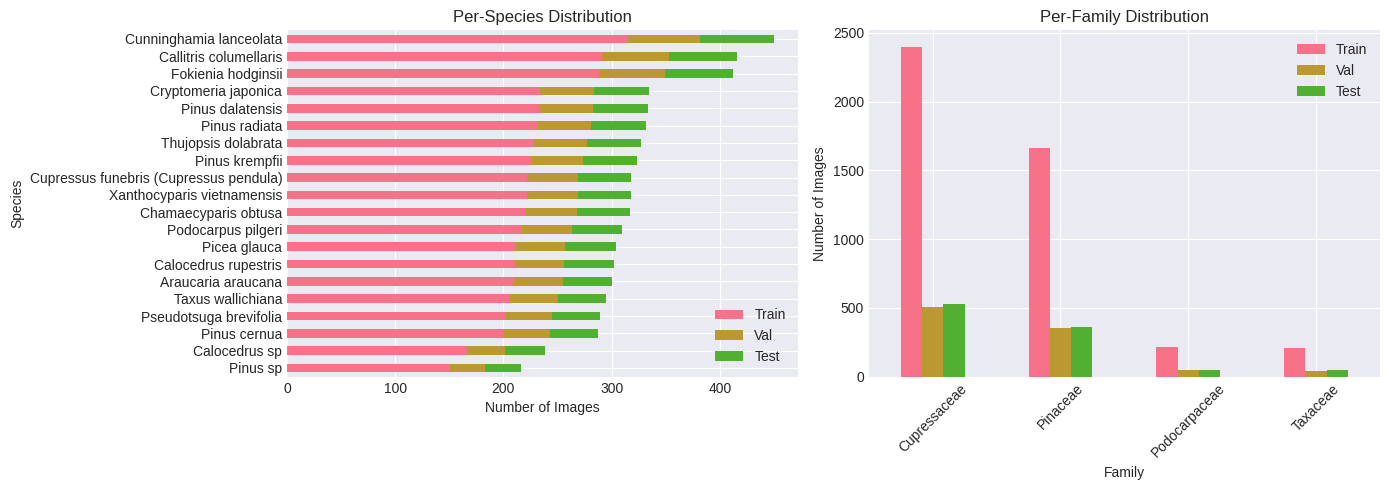

In [12]:
# Visualize final distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Per-species distribution
df_train = pd.DataFrame(train_imgs)
df_val = pd.DataFrame(val_imgs)
df_test = pd.DataFrame(test_imgs)

species_counts = pd.DataFrame({
    'Species': df_images['species'].unique(),
    'Train': [len(df_train[df_train['species'] == s]) for s in df_images['species'].unique()],
    'Val': [len(df_val[df_val['species'] == s]) for s in df_images['species'].unique()],
    'Test': [len(df_test[df_test['species'] == s]) for s in df_images['species'].unique()],
}).sort_values('Train', ascending=True)

species_counts.plot(kind='barh', stacked=True, x='Species', ax=axes[0])
axes[0].set_title('Per-Species Distribution')
axes[0].set_xlabel('Number of Images')

# Per-family distribution
family_counts = pd.DataFrame({
    'Family': ['Cupressaceae', 'Pinaceae', 'Podocarpaceae', 'Taxaceae'],
    'Train': [len(df_train[df_train['family'] == f]) for f in ['Cupressaceae', 'Pinaceae', 'Podocarpaceae', 'Taxaceae']],
    'Val': [len(df_val[df_val['family'] == f]) for f in ['Cupressaceae', 'Pinaceae', 'Podocarpaceae', 'Taxaceae']],
    'Test': [len(df_test[df_test['family'] == f]) for f in ['Cupressaceae', 'Pinaceae', 'Podocarpaceae', 'Taxaceae']],
})

family_counts.plot(kind='bar', x='Family', ax=axes[1])
axes[1].set_title('Per-Family Distribution')
axes[1].set_ylabel('Number of Images')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/split_distribution.png", dpi=150)
plt.show()

## 9. Export Split Metadata

In [13]:
# Export split metadata for reproducibility
split_metadata = {
    'seed': RANDOM_SEED,
    'ratios': {
        'train': TRAIN_RATIO,
        'val': VAL_RATIO,
        'test': TEST_RATIO
    },
    'counts': {
        'train': len(train_imgs),
        'val': len(val_imgs),
        'test': len(test_imgs)
    },
    'per_family': {
        'Cupressaceae': {'train': len(df_train[df_train['family'] == 'Cupressaceae']),
                        'val': len(df_val[df_val['family'] == 'Cupressaceae']),
                        'test': len(df_test[df_test['family'] == 'Cupressaceae'])},
        'Pinaceae': {'train': len(df_train[df_train['family'] == 'Pinaceae']),
                    'val': len(df_val[df_val['family'] == 'Pinaceae']),
                    'test': len(df_test[df_test['family'] == 'Pinaceae'])},
        'Podocarpaceae': {'train': len(df_train[df_train['family'] == 'Podocarpaceae']),
                         'val': len(df_val[df_val['family'] == 'Podocarpaceae']),
                         'test': len(df_test[df_test['family'] == 'Podocarpaceae'])},
        'Taxaceae': {'train': len(df_train[df_train['family'] == 'Taxaceae']),
                    'val': len(df_val[df_val['family'] == 'Taxaceae']),
                    'test': len(df_test[df_test['family'] == 'Taxaceae'])}
    }
}

with open(f"{OUTPUT_DIR}/split_metadata.json", 'w') as f:
    json.dump(split_metadata, f, indent=2)

print(f"Split metadata saved to: {OUTPUT_DIR}/split_metadata.json")

Split metadata saved to: ../../data/split/split_metadata.json


## 10. Summary

In [14]:
print("=" * 60)
print("Phase 0 Complete!")
print("=" * 60)
print("\nOutputs created:")
print(f"  1. Dataset structure: {OUTPUT_DIR}/{{train,val,test}}/{{family}}/{{species}}/")
print(f"  2. Label mapping: {LABEL_MAPPING_PATH}")
print(f"  3. Split metadata: {OUTPUT_DIR}/split_metadata.json")
print(f"  4. Visualization: {OUTPUT_DIR}/split_distribution.png")
print("\nNext steps:")
print("  1. Run Phase -1 (Dataset Exploration) if not done")
print("  2. Proceed to Phase 1 (Core Implementation)")

Phase 0 Complete!

Outputs created:
  1. Dataset structure: ../../data/split/{train,val,test}/{family}/{species}/
  2. Label mapping: ../../data/species_to_family.json
  3. Split metadata: ../../data/split/split_metadata.json
  4. Visualization: ../../data/split/split_distribution.png

Next steps:
  1. Run Phase -1 (Dataset Exploration) if not done
  2. Proceed to Phase 1 (Core Implementation)
